# Part 3 of 6: Vision Transformer: Fine-Tuning Strategies

This notebook covers Section 10: three fine-tuning strategies for a pre-trained ViT-B/16 and an augmentation ablation, and the selection of the final ViT on the validation set.

Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from plantdisease.config import SHORT_NAMES, out_path
from plantdisease.data.dataset import prepare
from plantdisease.evaluate import (
    compare_seeds,
    mean_sd,
    per_class_f1,
    sd,
    seed_scores,
    stable_errors,
    training_cost,
)
from plantdisease.experiments import (
    BASE_VIT,
    VIT_EXPERIMENTS,
    changes_table,
    save_selected,
)
from plantdisease.models import build_model, count_params, set_trainable
from plantdisease.plots import finish, mean_curve
from plantdisease.predictions import predict_labels
from plantdisease.train import run

data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache

## 10. ViT-B/16 Fine-Tuning

**Model.** torchvision's ViT-B/16 with ImageNet-1K weights. The 224×224 image is cut into 14×14 = 196 patches of 16×16 pixels; together with a class token they pass through 12 self-attention blocks that relate every patch to every other patch (Lab 5). The ImageNet head is replaced by a 4-class linear layer (3,076 parameters); the model has 85.8 M parameters in total.

**Fine-tuning strategies.** All strategies first train **only the new head for 3 epochs**. From epoch 4 they differ only in which parameters are unfrozen:

| Strategy | Epochs 1–3 | Epochs 4–15 |
|---|---|---|
| **head only** | head | head; the backbone stays frozen |
| **partial** | head | last 2 encoder blocks, final LayerNorm and head |
| **full** | head | every parameter, including patch embedding, position embedding and class token |

An **augmentation ablation** repeats the partial strategy without training augmentation. Retraining on grayscale and background-removed photos (Zhouyang's input ablation) follows in notebook 05, Section 15.

**Training settings.** 15 epochs, batch size 16, AdamW with weight decay 0.01, constant learning rates: head 1e-3 in epochs 1–3, then head 1e-4 and unfrozen backbone 1e-5 (two parameter groups; the optimizer is rebuilt at the switch). Class-weighted cross-entropy (w_c = N / (K n_c), to offset the class imbalance), gradient-norm limit 1, mixed precision on CUDA, the checkpoint with the best validation macro-F1 is kept. **Early stopping** (an addition to Zhouyang's fixed 15 epochs): a run stops when the validation macro-F1 has not improved for 5 epochs of the fine-tuning stage, so strategies can train for different numbers of epochs; the tables report the epochs trained next to the training time. Seeds 62, 63 and 64; a strategy's three runs share the split, and the same seed gives the same initialisation and the same first three epochs for all strategies.

**Differences to Zhouyang's original runs.** The classes, the split and the preprocessing are the project's (notebook 01): the whole photo is resized to 224×224 instead of a 256 resize with a centre crop, and the training augmentation is the project's (flips, 90° rotations, mild brightness/contrast) instead of flips only. The "no augmentation" ablation switches this whole augmentation off.

### 10.0 The experiments

The four strategies are defined in `plantdisease/experiments.py` (`VIT_EXPERIMENTS`) as changes of one base recipe, `BASE_VIT`: partial fine-tuning of the last 2 encoder blocks. The base recipe follows the training settings above. Every notebook finds the recipe of a run by its name (`config_of`).

In [2]:
# the base recipe, and what each strategy changes
display(pd.Series(BASE_VIT.model_dump(), name="ViT-B/16 base recipe").to_frame())
changes_table(VIT_EXPERIMENTS, BASE_VIT)

,ViT-B/16 base recipe
arch,vit_b_16
lr,0.00001
batch_size,16
dropout,0.0
augment,True
class_weights,True
scheduler,constant
weight_decay,0.01
epochs,20
patience,5


,changes from the base recipe
ViT-B/16 head only,trainable_blocks=0
ViT-B/16 partial (last 2 blocks),(base recipe)
ViT-B/16 full fine-tuning,trainable_blocks=None
"ViT-B/16 partial, no augmentation",augment=False


### 10.1 Which parameters does each strategy train?

A check before training: the number of trainable parameters in each stage.

In [3]:
model = build_model(BASE_VIT)
total = count_params(model)
rows = []
for name, cfg in VIT_EXPERIMENTS.items():
    row = {"run": name}
    for stage in ("head", "finetune"):
        set_trainable(model, cfg, stage)
        row[f"trainable, {stage} stage"] = count_params(model, trainable_only=True)
    row["share of all parameters"] = f"{row['trainable, finetune stage'] / total:.2%}"
    rows.append(row)
del model
pd.DataFrame(rows).set_index("run")

,"trainable, head stage","trainable, finetune stage",share of all parameters
run,,,
ViT-B/16 head only,3076,3076,0.00%
ViT-B/16 partial (last 2 blocks),3076,14180356,16.53%
ViT-B/16 full fine-tuning,3076,85801732,100.00%
"ViT-B/16 partial, no augmentation",3076,14180356,16.53%


### 10.2 Training

Every configuration is trained with all three seeds (4 configurations × 3 seeds = 12 runs).

In [4]:
vit_histories = {name: run(name, data) for name in VIT_EXPERIMENTS}


===== ViT-B/16 head only (seed 62) =====
Epoch 1/20 [head] | train loss 0.3679 acc 0.8903 | val loss 0.1591 acc 0.9461 macro-F1 0.9332 | 33s
Epoch 2/20 [head] | train loss 0.1194 acc 0.9719 | val loss 0.1204 acc 0.9605 macro-F1 0.9508 | 17s
Epoch 3/20 [head] | train loss 0.0817 acc 0.9807 | val loss 0.0859 acc 0.9737 macro-F1 0.9691 | 17s
Epoch 4/20 [finetune] | train loss 0.0623 acc 0.9875 | val loss 0.0818 acc 0.9724 macro-F1 0.9670 | 17s
Epoch 5/20 [finetune] | train loss 0.0613 acc 0.9881 | val loss 0.0785 acc 0.9737 macro-F1 0.9692 | 18s
Epoch 6/20 [finetune] | train loss 0.0589 acc 0.9872 | val loss 0.0780 acc 0.9737 macro-F1 0.9696 | 18s
Epoch 7/20 [finetune] | train loss 0.0573 acc 0.9901 | val loss 0.0775 acc 0.9763 macro-F1 0.9731 | 18s
Epoch 8/20 [finetune] | train loss 0.0553 acc 0.9892 | val loss 0.0745 acc 0.9750 macro-F1 0.9714 | 18s
Epoch 9/20 [finetune] | train loss 0.0589 acc 0.9872 | val loss 0.0764 acc 0.9750 macro-F1 0.9718 | 18s
Epoch 10/20 [finetune] | train los

e:\Projects_2026\COMP7015_AI_Group_Project5-main\.venv\Lib\site-packages\torch\autograd\graph.py:1113: UserWarning: Flash Attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:159.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 4/20 [finetune] | train loss 0.0530 acc 0.9878 | val loss 0.0658 acc 0.9711 macro-F1 0.9665 | 24s
Epoch 5/20 [finetune] | train loss 0.0339 acc 0.9918 | val loss 0.0515 acc 0.9803 macro-F1 0.9773 | 23s
Epoch 6/20 [finetune] | train loss 0.0216 acc 0.9926 | val loss 0.0521 acc 0.9803 macro-F1 0.9774 | 23s
Epoch 7/20 [finetune] | train loss 0.0129 acc 0.9972 | val loss 0.0528 acc 0.9842 macro-F1 0.9821 | 23s
Epoch 8/20 [finetune] | train loss 0.0106 acc 0.9980 | val loss 0.0463 acc 0.9816 macro-F1 0.9791 | 23s
Epoch 9/20 [finetune] | train loss 0.0084 acc 0.9986 | val loss 0.0460 acc 0.9842 macro-F1 0.9816 | 24s
Epoch 10/20 [finetune] | train loss 0.0050 acc 0.9986 | val loss 0.0449 acc 0.9829 macro-F1 0.9789 | 24s
Epoch 11/20 [finetune] | train loss 0.0037 acc 0.9989 | val loss 0.0404 acc 0.9855 macro-F1 0.9824 | 24s
Epoch 12/20 [finetune] | train loss 0.0032 acc 0.9991 | val loss 0.0407 acc 0.9842 macro-F1 0.9811 | 25s
Epoch 13/20 [finetune] | train loss 0.0034 acc 0.9991 | val l

### 10.3 Validation results, cost and selection

The final ViT is the configuration with the highest **mean validation macro-F1 over the seeds**. The table also shows the training cost: trainable parameters in the fine-tuning stage, epochs trained (early stopping), total training time (all epochs, without validation) and the time per epoch.

In [5]:
rows = []
for name, hs in vit_histories.items():
    rows.append(
        {
            "run": name,
            "val macro-F1": mean_sd([max(h.val_f1) for h in hs]),
            "best epochs": ", ".join(str(int(np.argmax(h.val_f1)) + 1) for h in hs),
            **training_cost(name),
        }
    )
vit_validation = pd.DataFrame(rows).set_index("run")
vit_validation.to_csv(out_path("vit_validation.csv"))

mean_val = {n: np.mean([max(h.val_f1) for h in hs]) for n, hs in vit_histories.items()}
BEST_VIT = max(mean_val, key=mean_val.get)
# OUT_DIR/final_models.json, read by notebooks 04-06
save_selected("vit_b_16", BEST_VIT)
print("Selected ViT:", BEST_VIT)
vit_validation

Selected ViT: ViT-B/16 full fine-tuning


,val macro-F1,best epochs,trainable params,epochs trained,train time (s),train s/epoch
run,,,,,,
ViT-B/16 head only,0.9742 ± 0.0022,"19, 5, 4",3076,13.0 ± 6.1,220.4 ± 87.2,17.297855
ViT-B/16 partial (last 2 blocks),0.9870 ± 0.0010,"16, 13, 10",14180356,17.7 ± 2.5,373.1 ± 52.8,21.119606
ViT-B/16 full fine-tuning,0.9963 ± 0.0004,"13, 8, 10",85801732,15.3 ± 2.5,595.3 ± 116.4,38.691950
"ViT-B/16 partial, no augmentation",0.9851 ± 0.0013,"12, 10, 12",14180356,16.3 ± 1.2,339.3 ± 34.9,20.739695


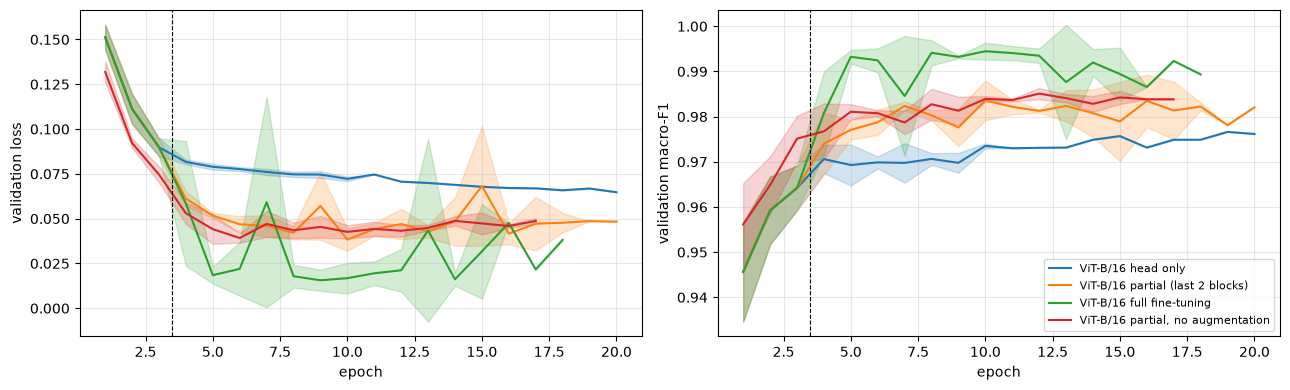

In [6]:
# Learning curves: mean over the seeds, shaded ± sd; dashed line: switch from head-only to fine-tuning
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k, (name, hs) in enumerate(vit_histories.items()):
    for ax, key in zip(axes, ("val_loss", "val_f1"), strict=True):
        epochs, mean, spread, _ = mean_curve(hs, key)
        ax.plot(epochs, mean, color=f"C{k}", label=name)
        ax.fill_between(epochs, mean - spread, mean + spread, color=f"C{k}", alpha=0.2)
for ax, label in zip(axes, ("validation loss", "validation macro-F1"), strict=True):
    ax.axvline(BASE_VIT.head_epochs + 0.5, color="black", linestyle="--", linewidth=0.8)
    ax.set_xlabel("epoch")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[1].legend(fontsize=8)
finish("vit_learning_curves.png")

### 10.4 Test results of all strategies (after selection)

The selection above uses only the validation set. Afterwards, every strategy is evaluated once on the test set, as in Zhouyang's comparison, to show what the strategies achieve and cost. Strategies trained with the same seed share the initialisation and the first three epochs, so they are also compared seed by seed. The table of errors counts the test photos that every seed misclassifies and those misclassified at least once.

In [7]:
y_test = data.y_test
# predicted classes on the test set: vit_preds[strategy] is an array (seeds, N)
vit_preds = predict_labels(VIT_EXPERIMENTS, {"test": data.images[data.test_idx]})[
    "test"
]
test_f1 = seed_scores(vit_preds, y_test)  # macro-F1 of every seed
rows = []
for name, preds in vit_preds.items():
    rows.append(
        {
            "run": name,
            "test accuracy": mean_sd((preds == y_test).mean(1)),
            "test macro-F1": mean_sd(test_f1[name]),
            **stable_errors(preds, y_test),
            "train time (s)": training_cost(name)["train time (s)"],
        }
    )
vit_test = pd.DataFrame(rows).set_index("run")
vit_test.to_csv(out_path("vit_strategies_test.csv"))
vit_test

,test accuracy,test macro-F1,errors per seed,wrong in every seed,wrong at least once,train time (s)
run,,,,,,
ViT-B/16 head only,0.9815 ± 0.0046,0.9772 ± 0.0056,"12, 18, 12",11,19,220.4 ± 87.2
ViT-B/16 partial (last 2 blocks),0.9872 ± 0.0020,0.9839 ± 0.0021,"8, 10, 11",7,14,373.1 ± 52.8
ViT-B/16 full fine-tuning,0.9934 ± 0.0013,0.9917 ± 0.0013,"5, 4, 6",3,8,595.3 ± 116.4
"ViT-B/16 partial, no augmentation",0.9819 ± 0.0028,0.9764 ± 0.0033,"16, 13, 12",12,16,339.3 ± 34.9


In [8]:
# Same-seed comparisons on the test set (A - B in macro-F1)
names = list(VIT_EXPERIMENTS)
pairs = {
    "partial vs. head only": (names[1], names[0]),
    "full vs. partial": (names[2], names[1]),
    "augmentation vs. none (partial)": (names[1], names[3]),
}
vit_comparison = pd.DataFrame(
    {label: compare_seeds(test_f1[a], test_f1[b]) for label, (a, b) in pairs.items()}
).T
vit_comparison.to_csv(out_path("vit_strategy_comparison.csv"))
vit_comparison

,A - B (mean),A - B (sd),A higher in
partial vs. head only,0.006728,0.005872,3 of 3 seeds
full vs. partial,0.007747,0.00222,3 of 3 seeds
augmentation vs. none (partial),0.007468,0.005382,3 of 3 seeds


,healthy,Bacterial_spot,Early_blight,Late_blight
ViT-B/16 head only,1.0,0.9953,0.9525,0.9609
ViT-B/16 partial (last 2 blocks),1.0,0.9979,0.9675,0.9702
ViT-B/16 full fine-tuning,1.0,0.9990,0.9831,0.9846
"ViT-B/16 partial, no augmentation",1.0,0.9995,0.9535,0.9528


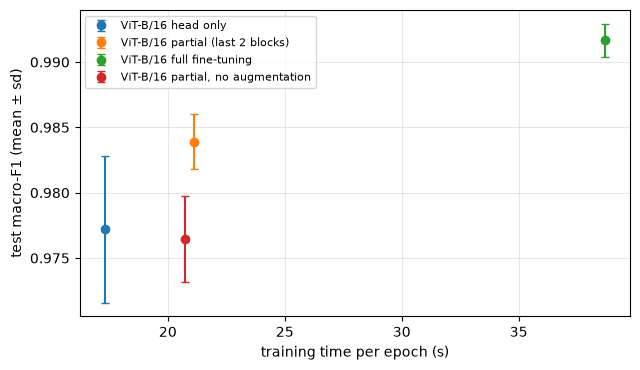

In [9]:
# Per-class test F1 (mean over seeds) and the accuracy-cost trade-off of the strategies
per_class = pd.DataFrame(
    {name: per_class_f1(preds, y_test) for name, preds in vit_preds.items()},
    index=SHORT_NAMES,
).T
display(per_class.round(4))

cost = pd.DataFrame(
    [training_cost(n) for n in VIT_EXPERIMENTS], index=list(VIT_EXPERIMENTS)
)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for k, name in enumerate(VIT_EXPERIMENTS):
    ax.errorbar(
        cost.at[name, "train s/epoch"],
        test_f1[name].mean(),
        yerr=sd(test_f1[name]),
        fmt="o",
        color=f"C{k}",
        label=name,
        capsize=3,
    )
ax.set_xlabel("training time per epoch (s)")
ax.set_ylabel("test macro-F1 (mean ± sd)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
finish("vit_strategy_cost.png")